# Target Variable Analysis
### What is a target variable?
A target variable is the column that a Machine Learning model is trained to predict. It is also called the dependent variable or label.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv", encoding="cp1252")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (541909, 8)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Classification target analysis
Classification is used when the target contains categories.

For example, a company may want to predict whether an invoice is a cancellation or a normal invoice.

In [2]:
df["InvoiceType"] = np.where(
    df["InvoiceNo"].astype(str).str.startswith("C"),
    "Cancellation",
    "Regular"
)

print(df["InvoiceType"].head())

0    Regular
1    Regular
2    Regular
3    Regular
4    Regular
Name: InvoiceType, dtype: str


### Class counts
Class counts tell us how many records belong to each category.

In [3]:
class_counts = df["InvoiceType"].value_counts()

print(class_counts)

InvoiceType
Regular         532621
Cancellation      9288
Name: count, dtype: int64


### Class percentages
Counts alone do not tell us the proportion of each class. We can calculate percentages:

In [4]:
class_percentages = (
    df["InvoiceType"]
    .value_counts(normalize=True)
    .mul(100)
)

print(class_percentages.round(2))

InvoiceType
Regular         98.29
Cancellation     1.71
Name: proportion, dtype: float64


### Visualize class distribution

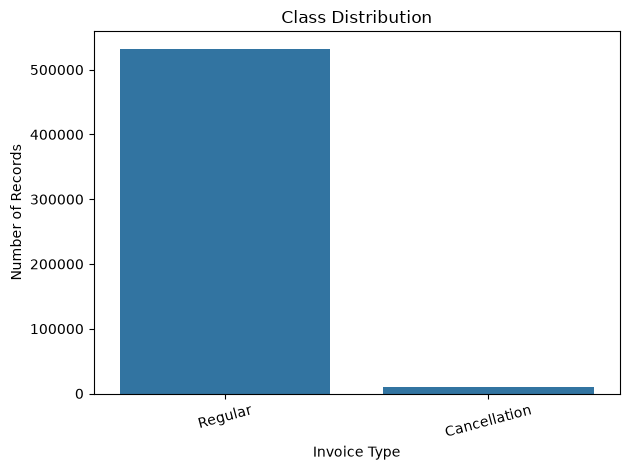

In [5]:
sns.countplot(data=df, x="InvoiceType")

plt.title("Class Distribution")
plt.xlabel("Invoice Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Understand class imbalance
Class imbalance occurs when one class has substantially more records than another.

### Example:
If 90% of records are Regular, a model that always predicts Regular could achieve 90% accuracy while failing to identify any cancellations.

## Regression target analysis
Regression is used when the target is a numerical value.

For example, a retailer might want to predict the sales value of a transaction line.
#### Create a numerical target
The Online Retail dataset does not have a predefined Sales column. We can calculate a line value for exploration:

In [6]:
df["LineValue"] = df["Quantity"] * df["UnitPrice"]

print(df["LineValue"].head())

0    15.30
1    20.34
2    22.00
3    20.34
4    20.34
Name: LineValue, dtype: float64


### Calculate descriptive statistics

In [7]:
target = df["LineValue"].dropna()

print("Mean:", target.mean())
print("Median:", target.median())
print("Variance:", target.var())
print("Standard Deviation:", target.std())
print("Skewness:", target.skew())
print("Minimum:", target.min())
print("Maximum:", target.max())

Mean: 17.987794876999644
Median: 9.75
Variance: 143497.64000527473
Standard Deviation: 378.8108235059747
Skewness: -0.9643891765707857
Minimum: -168469.6
Maximum: 168469.6


#### Plot the target distribution

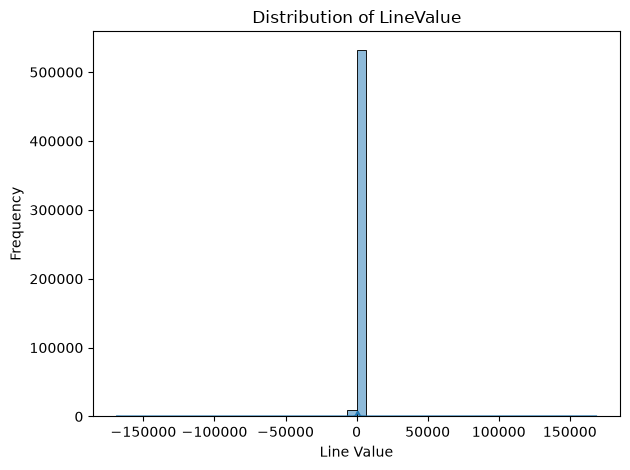

In [8]:
sns.histplot(target, bins=50, kde=True)

plt.title("Distribution of LineValue")
plt.xlabel("Line Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Check target outliers

In [9]:
Q1 = target.quantile(0.25)
Q3 = target.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = target[
    (target < lower_bound) |
    (target > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))

Lower bound: -17.599999999999998
Upper bound: 38.39999999999999
Number of potential outliers: 44997
